# Barrido del tamaño de ventana con GRU, Mirai sin src_ip

Entrena el autoencoder GRU con distintos tamaños de ventana W y registra el número de ventanas de entrenamiento, la memoria que ocupan, el tiempo de entrenamiento y el AUC. Repite el barrido de Mirai sin `src_ip` en la entrada, lo que confirma la fuga de información.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import time

SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

In [2]:
DATA_PATH = Path("../../data/flows.csv")
df = pd.read_csv(DATA_PATH)

# Ventanas por IP de origen, ordenadas por flow_start. src_ip solo sirve para agrupar, no es una entrada
df['group'] = df['src_ip']
df['order'] = df['flow_start']
df['is_attack'] = df['label']
X = pd.get_dummies(df.drop(columns=['class_name', 'flow_start', 'label', 'src_ip', 'group', 'order', 'is_attack']), columns=['state'])
meta = df[['group', 'order', 'is_attack']]
print(X.shape)
print(list(X.columns))

(1006776, 15)
['duration', 'n_pkts', 'n_bytes', 'f_pkts', 'f_bytes', 'b_pkts', 'b_bytes', 'avg_pkt_size', 'state_DNS', 'state_HTTP', 'state_HTTPS', 'state_OTHER', 'state_SSH', 'state_TCP_OTHER', 'state_UDP_OTHER']


In [3]:
def build_windows(X, meta, W, stride=1):
    meta = meta.copy()
    meta['pos'] = meta.groupby('group').cumcount()
    meta['grp_size'] = meta.groupby('group')['group'].transform('size')
    order_idx = meta.sort_values(['group', 'order']).index
    X = X.loc[order_idx].reset_index(drop=True)
    meta = meta.loc[order_idx].reset_index(drop=True)

    train_mask = (meta['pos'] < (0.8 * meta['grp_size'])).to_numpy()
    scaler = MinMaxScaler().fit(X.to_numpy()[train_mask])
    Xs = scaler.transform(X.to_numpy()).astype('float32')
    attack_arr = meta['is_attack'].to_numpy()
    group_arr = meta['group'].to_numpy()

    train_windows, test_windows, test_labels = [], [], []
    for gid in pd.unique(group_arr):
        sel = np.where(group_arr == gid)[0]
        is_train = train_mask[sel]
        train_idxs = sel[is_train]
        test_idxs = sel[~is_train]

        n_tr = len(train_idxs) - W + 1
        if n_tr > 0:
            attack_tr = attack_arr[train_idxs]
            cums = np.concatenate([[0], np.cumsum(attack_tr)])
            window_sums = cums[W:] - cums[:-W]
            for i in np.where(window_sums == 0)[0][::stride]:
                train_windows.append(Xs[train_idxs[i:i + W]])

        n_te = len(test_idxs) - W + 1
        if n_te > 0:
            attack_te = attack_arr[test_idxs]
            cums = np.concatenate([[0], np.cumsum(attack_te)])
            window_sums = cums[W:] - cums[:-W]
            for i in range(0, n_te, stride):
                test_windows.append(Xs[test_idxs[i:i + W]])
                test_labels.append(int(window_sums[i] > 0))

    X_train_w = np.array(train_windows) if train_windows else np.empty((0, W, X.shape[1]))
    X_test_w = np.array(test_windows) if test_windows else np.empty((0, W, X.shape[1]))
    y_test_w = np.array(test_labels)
    return X_train_w, X_test_w, y_test_w

In [4]:
DATASET_KEY = 'mirai_noleak'
STRIDE = 1
TITLE = 'Barrido de W -- GRU, Mirai (sin src_ip como feature)'
EPOCHS = 100
PATIENCE = 15

In [5]:
CSV_PATH = Path.cwd() / f"_barrido_w_checkpoint_{DATASET_KEY}.csv"
results = []

def run_one(W, stride):
    t0 = time.perf_counter()
    X_train_w, X_test_w, y_test_w = build_windows(X, meta, W, stride=stride)
    build_time = time.perf_counter() - t0

    if X_train_w.shape[0] < 10 or X_test_w.shape[0] < 10:
        row = {'W': W, 'ventanas_train': X_train_w.shape[0], 'ventanas_test': X_test_w.shape[0],
               'memoria_train_MB': round(X_train_w.nbytes / 1e6, 2), 'epocas': None,
               'tiempo_construccion_s': round(build_time, 1), 'tiempo_entrenamiento_s': None,
               'roc_auc': None}
        print(f"W={W}: ventanas insuficientes (train={X_train_w.shape[0]}, test={X_test_w.shape[0]}) -> se omite")
    else:
        input_dim = X_train_w.shape[2]
        bottleneck = 16
        tf.keras.utils.set_random_seed(SEED)

        inputs = keras.Input(shape=(W, input_dim))
        x = layers.GRU(32, return_sequences=True)(inputs)
        x = layers.GRU(bottleneck, return_sequences=False)(x)
        x = layers.RepeatVector(W)(x)
        x = layers.GRU(bottleneck, return_sequences=True)(x)
        x = layers.GRU(32, return_sequences=True)(x)
        outputs = layers.TimeDistributed(layers.Dense(input_dim, activation='sigmoid'))(x)

        autoencoder = keras.Model(inputs, outputs)
        autoencoder.compile(optimizer='adam', loss='mse')

        t1 = time.perf_counter()
        history = autoencoder.fit(
            X_train_w, X_train_w,
            epochs=EPOCHS, batch_size=64, validation_split=0.1,
            callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)],
            verbose=0,
        )
        train_time = time.perf_counter() - t1

        def reconstruction_error(Xw):
            return np.mean(np.square(Xw - autoencoder.predict(Xw, verbose=0)), axis=(1, 2))

        err_test = reconstruction_error(X_test_w)
        auc = roc_auc_score(y_test_w, err_test)
        mem_mb = X_train_w.nbytes / 1e6

        row = {
            'W': W,
            'ventanas_train': X_train_w.shape[0],
            'ventanas_test': X_test_w.shape[0],
            'memoria_train_MB': round(mem_mb, 2),
            'epocas': len(history.history['loss']),
            'tiempo_construccion_s': round(build_time, 1),
            'tiempo_entrenamiento_s': round(train_time, 1),
            'roc_auc': round(float(auc), 4),
        }
        print(f"W={W}: ventanas_train={X_train_w.shape[0]}, memoria={mem_mb:.1f}MB, "
              f"epocas={len(history.history['loss'])}, tiempo={train_time:.1f}s, AUC={auc:.4f}")

        del autoencoder
        tf.keras.backend.clear_session()

    results.append(row)
    pd.DataFrame(results).to_csv(CSV_PATH, index=False)
    return row

In [6]:
run_one(2, STRIDE)

W=2: ventanas_train=6223, memoria=0.7MB, epocas=100, tiempo=77.5s, AUC=0.9211


{'W': 2,
 'ventanas_train': 6223,
 'ventanas_test': 201210,
 'memoria_train_MB': 0.75,
 'epocas': 100,
 'tiempo_construccion_s': 3.3,
 'tiempo_entrenamiento_s': 77.5,
 'roc_auc': 0.9211}

In [7]:
run_one(3, STRIDE)

W=3: ventanas_train=6119, memoria=1.1MB, epocas=100, tiempo=99.0s, AUC=0.9026


{'W': 3,
 'ventanas_train': 6119,
 'ventanas_test': 201117,
 'memoria_train_MB': 1.1,
 'epocas': 100,
 'tiempo_construccion_s': 3.7,
 'tiempo_entrenamiento_s': 99.0,
 'roc_auc': 0.9026}

In [8]:
run_one(4, STRIDE)

W=4: ventanas_train=6022, memoria=1.4MB, epocas=100, tiempo=128.9s, AUC=0.7723


{'W': 4,
 'ventanas_train': 6022,
 'ventanas_test': 201033,
 'memoria_train_MB': 1.45,
 'epocas': 100,
 'tiempo_construccion_s': 3.3,
 'tiempo_entrenamiento_s': 128.9,
 'roc_auc': 0.7723}

In [9]:
run_one(5, STRIDE)

W=5: ventanas_train=5927, memoria=1.8MB, epocas=100, tiempo=151.5s, AUC=0.8211


{'W': 5,
 'ventanas_train': 5927,
 'ventanas_test': 200957,
 'memoria_train_MB': 1.78,
 'epocas': 100,
 'tiempo_construccion_s': 3.5,
 'tiempo_entrenamiento_s': 151.5,
 'roc_auc': 0.8211}

In [10]:
run_one(7, STRIDE)

W=7: ventanas_train=5742, memoria=2.4MB, epocas=100, tiempo=146.0s, AUC=0.7319


{'W': 7,
 'ventanas_train': 5742,
 'ventanas_test': 200825,
 'memoria_train_MB': 2.41,
 'epocas': 100,
 'tiempo_construccion_s': 3.4,
 'tiempo_entrenamiento_s': 146.0,
 'roc_auc': 0.7319}

In [11]:
run_one(10, STRIDE)

W=10: ventanas_train=5481, memoria=3.3MB, epocas=100, tiempo=225.5s, AUC=0.6247


{'W': 10,
 'ventanas_train': 5481,
 'ventanas_test': 200665,
 'memoria_train_MB': 3.29,
 'epocas': 100,
 'tiempo_construccion_s': 3.6,
 'tiempo_entrenamiento_s': 225.5,
 'roc_auc': 0.6247}

In [12]:
run_one(15, STRIDE)

W=15: ventanas_train=5094, memoria=4.6MB, epocas=30, tiempo=94.0s, AUC=0.4122


{'W': 15,
 'ventanas_train': 5094,
 'ventanas_test': 200465,
 'memoria_train_MB': 4.58,
 'epocas': 30,
 'tiempo_construccion_s': 3.5,
 'tiempo_entrenamiento_s': 94.0,
 'roc_auc': 0.4122}

In [13]:
run_one(20, STRIDE)

W=20: ventanas_train=4755, memoria=5.7MB, epocas=22, tiempo=80.4s, AUC=0.4151


{'W': 20,
 'ventanas_train': 4755,
 'ventanas_test': 200314,
 'memoria_train_MB': 5.71,
 'epocas': 22,
 'tiempo_construccion_s': 3.6,
 'tiempo_entrenamiento_s': 80.4,
 'roc_auc': 0.4151}

In [14]:
run_one(30, STRIDE)

W=30: ventanas_train=4208, memoria=7.6MB, epocas=33, tiempo=162.5s, AUC=0.3666


{'W': 30,
 'ventanas_train': 4208,
 'ventanas_test': 200124,
 'memoria_train_MB': 7.57,
 'epocas': 33,
 'tiempo_construccion_s': 4.0,
 'tiempo_entrenamiento_s': 162.5,
 'roc_auc': 0.3666}

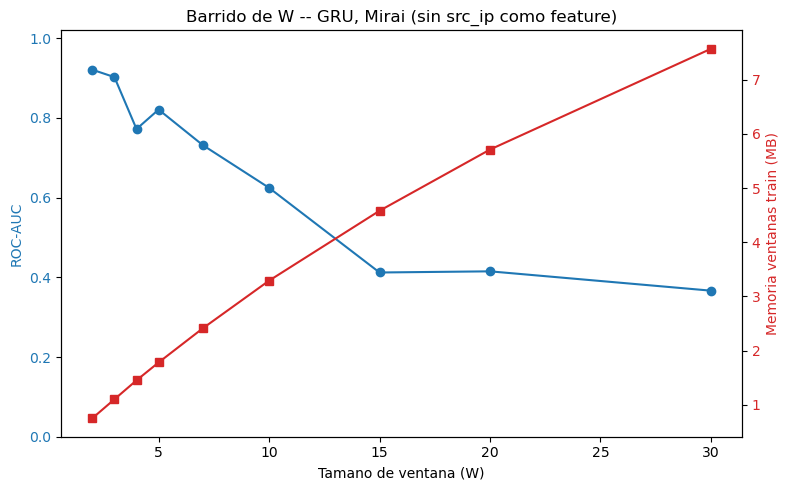

,W,ventanas_train,ventanas_test,memoria_train_MB,epocas,tiempo_construccion_s,tiempo_entrenamiento_s,roc_auc
0,2,6223,201210,0.75,100,3.3,77.5,0.9211
1,3,6119,201117,1.10,100,3.7,99.0,0.9026
2,4,6022,201033,1.45,100,3.3,128.9,0.7723
3,5,5927,200957,1.78,100,3.5,151.5,0.8211
4,7,5742,200825,2.41,100,3.4,146.0,0.7319
5,10,5481,200665,3.29,100,3.6,225.5,0.6247
6,15,5094,200465,4.58,30,3.5,94.0,0.4122
7,20,4755,200314,5.71,22,3.6,80.4,0.4151
8,30,4208,200124,7.57,33,4.0,162.5,0.3666


In [15]:
import matplotlib.pyplot as plt

df_res = pd.DataFrame(results)
df_plot = df_res.dropna(subset=['roc_auc'])

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.set_xlabel('Tamano de ventana (W)')
ax1.set_ylabel('ROC-AUC', color='tab:blue')
ax1.plot(df_plot['W'], df_plot['roc_auc'], marker='o', color='tab:blue', label='ROC-AUC')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_ylim(0, 1.02)

ax2 = ax1.twinx()
ax2.set_ylabel('Memoria ventanas train (MB)', color='tab:red')
ax2.plot(df_plot['W'], df_plot['memoria_train_MB'], marker='s', color='tab:red', label='Memoria (MB)')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title(TITLE)
fig.tight_layout()
plt.show()
df_res

## Resultado

| W | ventanas train | memoria | AUC (sin fuga) | AUC (con fuga) |
|---|---|---|---|---|
| 2 | 6.223 | 0.7 MB | **0.9211** | 0.8552 |
| 3 (elegido) | 6.119 | 1.1 MB | 0.9026 | 0.8377 |
| 4 | 6.022 | 1.4 MB | 0.7723 | 0.8188 |
| 5 | 5.927 | 1.8 MB | 0.8211 | 0.8637 |
| 7 | 5.742 | 2.4 MB | 0.7319 | 0.8983 |
| 10 | 5.481 | 3.3 MB | 0.6247 | 0.9379 |
| 15 | 5.094 | 4.6 MB | 0.4122 | 0.9606 |
| 20 | 4.755 | 5.7 MB | 0.4151 | 0.9830 |
| 30 | 4.208 | 7.6 MB | 0.3666 | 1.0000 |

Sin `src_ip` la tendencia se invierte y el AUC baja al aumentar W. Se elige W = 3, con un AUC muy próximo al de W = 2.